# Week 02 · Machine Learning
# Classification Evaluation & Performance Metrics

**Program:** Data Science & AI — Professional Training Program  
**Business case:** AdventureWorks  
**Estimated classroom time:** 5 hours  
**Level:** Beginner to early intermediate  
**Notebook ID:** ML_11

---

## Instructor and learner guide

This session develops a disciplined approach to evaluating classification models. We will continue the AdventureWorks order-return case introduced in **ML_10 — Logistic Regression & Classification Fundamentals**.

The central question is not simply whether a model is accurate. It is whether its errors, ranking ability, and probability estimates are acceptable for the business decision it supports.

**Working convention:** class `1` means *Returned* and is the positive class. Class `0` means *Not returned*.

All records in this notebook are synthetic and reproducible. They are designed for learning and do not represent actual AdventureWorks customers or operational performance.

## Learning outcomes

By the end of this session, learners will be able to:

1. Explain why model evaluation must use data that was not used for fitting.
2. Read a confusion matrix and identify TP, TN, FP, and FN.
3. Calculate and interpret accuracy, precision, recall, specificity, F1, and balanced accuracy.
4. Explain macro, micro, and weighted averaging for classification metrics.
5. Compare ROC curves, ROC-AUC, precision-recall curves, and average precision.
6. Explain why the positive-class prevalence matters when interpreting precision-recall results.
7. Compare model performance at different decision thresholds.
8. Select an operating threshold using business costs and operational capacity.
9. Assess probability quality using calibration concepts and the Brier score.
10. Communicate model performance with a concise, evidence-based evaluation report.

## Table of contents

1. Evaluation as a business decision
2. Rebuild the AdventureWorks evaluation baseline
3. Confusion matrix: the four possible outcomes
4. Core classification metrics
5. Why accuracy can be misleading
6. Metrics for both classes and averaging strategies
7. Ranking performance: ROC curve and ROC-AUC
8. Precision-recall analysis and average precision
9. Threshold analysis and business trade-offs
10. Probability quality and calibration
11. A structured model evaluation report
12. Common evaluation mistakes
13. Mini project: recommend an operating policy
14. Knowledge check and instructor solutions

## 1. Evaluation as a business decision

AdventureWorks uses a classification model to identify orders that may be returned. The operations team may review flagged orders, improve product information, or prepare support capacity.

A model can make two types of mistakes:

- **False positive:** an order is flagged as likely to be returned, but it is not returned. This may waste review time.
- **False negative:** an order is predicted not to be returned, but it is returned. The team may miss an opportunity to prevent or prepare for the return.

These mistakes do not always have the same business cost. Evaluation helps us understand the trade-offs before a model is used in a real process.

### A useful evaluation principle

A metric is not good or bad by itself. It is useful when it answers a clearly stated question about model performance.

### Exercise 1 — Connect errors to business impact

For each case, identify the error type and one possible operational consequence.

1. The model flags an order for review, but the customer keeps it.
2. The model predicts that an order will not be returned, but the customer returns it.
3. The operations team can manually review only 100 orders per day. Which information would help them choose a practical threshold?

**Discussion:** Which error could be more expensive for AdventureWorks? The answer depends on the cost of review, the cost of a missed return, and the action taken after a flag.

## 2. Rebuild the AdventureWorks evaluation baseline

We will recreate the same business dataset and modeling approach used in ML_10 so the two notebooks remain connected. We will use a training set, a validation set, and a final test set:

- **Training set:** fit the preprocessing steps and model.
- **Validation set:** compare operating thresholds and make development decisions.
- **Test set:** provide a final evaluation after decisions are complete.

The test set must not guide threshold selection or model tuning. Repeatedly making decisions based on test results turns the test set into part of the development process.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

n_orders = 3000

product_category = rng.choice(
    ["Electronics", "Home", "Accessories", "Office"],
    size=n_orders,
    p=[0.34, 0.27, 0.24, 0.15]
)
sales_channel = rng.choice(
    ["Website", "Mobile App", "Store", "Partner"],
    size=n_orders,
    p=[0.38, 0.30, 0.20, 0.12]
)
customer_segment = rng.choice(
    ["Consumer", "Small Business", "Corporate"],
    size=n_orders,
    p=[0.62, 0.23, 0.15]
)
payment_method = rng.choice(
    ["Card", "Digital Wallet", "Bank Transfer", "Cash on Delivery"],
    size=n_orders,
    p=[0.48, 0.27, 0.13, 0.12]
)
region = rng.choice(["North", "South", "East", "West"], size=n_orders)

quantity = rng.integers(1, 8, size=n_orders)
unit_price = np.round(rng.lognormal(mean=3.7, sigma=0.65, size=n_orders), 2)
discount_pct = np.round(
    rng.choice([0, 0.05, 0.10, 0.15, 0.20], size=n_orders,
               p=[0.40, 0.18, 0.22, 0.13, 0.07]), 2
)
customer_tenure_months = rng.integers(1, 97, size=n_orders)
prior_orders = rng.poisson(lam=5, size=n_orders)
days_since_last_order = rng.integers(1, 181, size=n_orders)

order_value = quantity * unit_price * (1 - discount_pct)

logit = (
    -2.15
    + 0.48 * (product_category == "Electronics")
    + 0.38 * (payment_method == "Cash on Delivery")
    + 0.30 * (sales_channel == "Partner")
    + 0.22 * (discount_pct >= 0.15)
    + 0.18 * (quantity >= 5)
    - 0.018 * customer_tenure_months
    - 0.055 * prior_orders
    + 0.0025 * days_since_last_order
)
return_probability = 1 / (1 + np.exp(-logit))
returned = rng.binomial(1, return_probability)

orders = pd.DataFrame({
    "order_id": [f"AW-{50001 + i}" for i in range(n_orders)],
    "product_category": product_category,
    "sales_channel": sales_channel,
    "customer_segment": customer_segment,
    "payment_method": payment_method,
    "region": region,
    "quantity": quantity,
    "unit_price": unit_price,
    "discount_pct": discount_pct,
    "order_value": np.round(order_value, 2),
    "customer_tenure_months": customer_tenure_months,
    "prior_orders": prior_orders,
    "days_since_last_order": days_since_last_order,
    "returned": returned
})

# Add a small amount of missingness to selected input columns.
for column in ["unit_price", "customer_segment", "region"]:
    missing_indices = rng.choice(orders.index, size=35, replace=False)
    orders.loc[missing_indices, column] = np.nan

display(orders.head())
print(f"Dataset shape: {orders.shape}")

,order_id,product_category,sales_channel,customer_segment,payment_method,region,quantity,unit_price,discount_pct,order_value,customer_tenure_months,prior_orders,days_since_last_order,returned
0,AW-50001,Accessories,Store,Consumer,Bank Transfer,West,7,102.36,0.00,716.52,90,4,143,0
1,AW-50002,Home,Mobile App,Consumer,Card,East,6,127.33,0.15,649.38,52,3,40,0
2,AW-50003,Office,Website,Consumer,Digital Wallet,East,5,50.14,0.05,238.16,79,1,116,0
3,AW-50004,Accessories,Store,Consumer,Card,South,3,18.21,0.00,54.63,25,8,92,1
4,AW-50005,Electronics,Website,Consumer,Card,West,5,128.01,0.10,576.04,74,5,10,0


Dataset shape: (3000, 14)


### Inspect the target and available features

The target distribution tells us how common returned orders are. This matters because a model can appear strong on accuracy when one class is much more common than the other.

We also define the prediction-time boundary. The model is assumed to score an order when it is placed. Only information available at that moment is eligible as a feature.

In [2]:
target = "returned"

numeric_features = [
    "quantity", "unit_price", "discount_pct", "order_value",
    "customer_tenure_months", "prior_orders", "days_since_last_order"
]
categorical_features = [
    "product_category", "sales_channel", "customer_segment",
    "payment_method", "region"
]
feature_columns = numeric_features + categorical_features

X = orders[feature_columns].copy()
y = orders[target].copy()

class_summary = y.value_counts().sort_index().rename(index={
    0: "Not returned (0)", 1: "Returned (1)"
})
display(pd.DataFrame({
    "orders": class_summary,
    "percentage": y.value_counts(normalize=True).sort_index().values * 100
}, index=class_summary.index).round(2))

print("Positive class prevalence:", round(y.mean(), 3))

,orders,percentage
returned,,
Not returned (0),2772,92.4
Returned (1),228,7.6


Positive class prevalence: 0.076


### Create separate training, validation, and test sets

We use stratification to preserve approximately the same class proportions in each split. The first split reserves 20% for the test set. The remaining 80% is divided into training and validation sets.

The validation set is used for threshold analysis. The final test set remains untouched until the operating policy is selected.

In [3]:
from sklearn.model_selection import train_test_split

X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development,
    test_size=0.25, random_state=RANDOM_STATE, stratify=y_development
)

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_validation), len(X_test)],
    "positive_rate": [y_train.mean(), y_validation.mean(), y_test.mean()]
}, index=["Training", "Validation", "Test"])

display(split_summary.round(3))

,rows,positive_rate
Training,1800,0.076
Validation,600,0.075
Test,600,0.077


### Fit the same Logistic Regression pipeline

Preprocessing is fitted only on the training data. The pipeline keeps imputation, scaling, encoding, and classification together. This reduces the risk of accidentally fitting preprocessing steps on validation or test observations.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

model.fit(X_train, y_train)
print("Model fitted using training data.")

Model fitted using training data.


In [5]:
# Obtain probabilities for the positive class (Returned = 1).
positive_class_index = list(model.named_steps["classifier"].classes_).index(1)

validation_probabilities = model.predict_proba(X_validation)[:, positive_class_index]
test_probabilities = model.predict_proba(X_test)[:, positive_class_index]

# The default threshold is 0.50. We will examine its performance first.
DEFAULT_THRESHOLD = 0.50
validation_predictions = (validation_probabilities >= DEFAULT_THRESHOLD).astype(int)
test_predictions = (test_probabilities >= DEFAULT_THRESHOLD).astype(int)

print("Validation observations:", len(y_validation))
print("Test observations:", len(y_test))
print("Default threshold:", DEFAULT_THRESHOLD)

Validation observations: 600
Test observations: 600
Default threshold: 0.5


### Exercise 2 — Evaluation design

1. What is the purpose of the training set?
2. Why do we keep a separate validation set?
3. Why should the test set not be used repeatedly to choose a threshold?
4. Why is stratification useful for this dataset?
5. Name one column that would be invalid if it were recorded only after a return.

**Instructor note:** Reinforce that a clean evaluation design is as important as selecting the metric.

## 3. Confusion matrix: the four possible outcomes

A confusion matrix compares actual labels with predicted labels. For binary classification, it contains four outcomes:

| | Predicted: Not returned | Predicted: Returned |
|---|---:|---:|
| **Actual: Not returned** | True Negative (TN) | False Positive (FP) |
| **Actual: Returned** | False Negative (FN) | True Positive (TP) |

- **True Positive (TP):** a returned order correctly identified.
- **True Negative (TN):** a non-returned order correctly identified.
- **False Positive (FP):** a non-returned order incorrectly flagged.
- **False Negative (FN):** a returned order missed by the model.

Always confirm which class is considered positive before interpreting these values.

Confusion matrix:
[[555   0]
 [ 45   0]]
TN=555 | FP=0 | FN=45 | TP=0


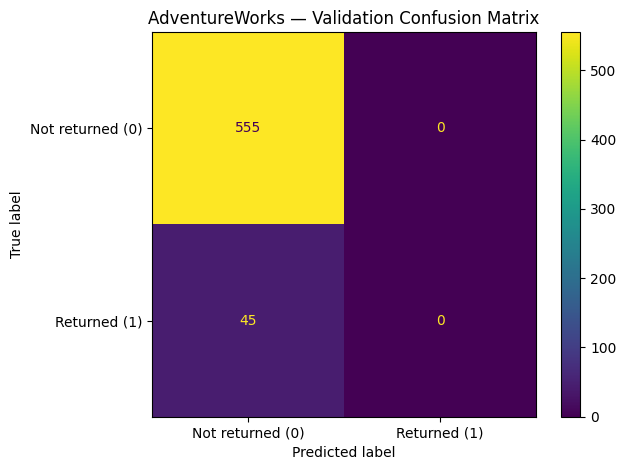

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_validation, validation_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Confusion matrix:")
print(cm)
print(f"TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}")

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not returned (0)", "Returned (1)"]
).plot(values_format="d")
plt.title("AdventureWorks — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

### Interpret the matrix in business terms

A confusion matrix does not tell us why an error occurred. It tells us how many errors of each type were made at a specific threshold.

For example, if false negatives are high, many actual returns are being missed. If false positives are high, the review team may receive many unnecessary alerts.

The next step is to convert these counts into metrics that can be compared across models and datasets.

### Exercise 3 — Confusion matrix interpretation

Using the confusion matrix above:

1. How many returned orders were correctly identified?
2. How many returned orders were missed?
3. How many orders were flagged incorrectly?
4. If the review team has limited capacity, why might a large FP count be a problem?
5. If preventing a return is valuable, why might a large FN count be a problem?

Write one sentence that summarizes the model's most important weakness at the default threshold.

## 4. Core classification metrics

### Accuracy

Accuracy is the proportion of all predictions that are correct.

\[
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
\]

It answers: *What fraction of all orders did the model classify correctly?*

Accuracy treats both classes equally in the overall count. It does not show which class the model handles well.

In [7]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_validation, validation_predictions)
print(f"Accuracy: {accuracy:.3f}")

Accuracy: 0.925


### Precision

Precision measures how many orders predicted as returned were actually returned.

\[
Precision = \frac{TP}{TP + FP}
\]

It answers: *When the model flags an order, how often is the flag correct?*

Higher precision can reduce unnecessary reviews. Precision is important when acting on a positive prediction is costly.

In [8]:
from sklearn.metrics import precision_score

precision = precision_score(
    y_validation, validation_predictions, pos_label=1, zero_division=0
)
print(f"Precision: {precision:.3f}")

Precision: 0.000


### Recall (Sensitivity)

Recall measures how many actual returned orders the model successfully identifies.

\[
Recall = \frac{TP}{TP + FN}
\]

It answers: *Out of all orders that were returned, how many did the model find?*

Higher recall means fewer positive cases are missed. Recall is important when missing a positive case has a high cost.

In [9]:
from sklearn.metrics import recall_score

recall = recall_score(
    y_validation, validation_predictions, pos_label=1, zero_division=0
)
print(f"Recall: {recall:.3f}")

Recall: 0.000


### Specificity

Specificity measures how many actual non-returned orders the model correctly identifies.

\[
Specificity = \frac{TN}{TN + FP}
\]

It answers: *Out of all orders that were not returned, how many did the model correctly leave unflagged?*

Specificity focuses on the negative class. It is useful when false alarms create operational cost.

In [10]:
specificity = tn / (tn + fp) if (tn + fp) else 0
print(f"Specificity: {specificity:.3f}")

Specificity: 1.000


### F1-score

F1 is the harmonic mean of precision and recall.

\[
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
\]

It provides one score when both precision and recall matter. Because it is a harmonic mean, a low value in either precision or recall pulls the F1-score down.

F1 does not include true negatives directly, so it should not be treated as a complete description of performance.

In [11]:
from sklearn.metrics import f1_score

f1 = f1_score(y_validation, validation_predictions, zero_division=0)
print(f"F1-score: {f1:.3f}")

F1-score: 0.000


### Balanced accuracy

Balanced accuracy is the average of recall for each class. In binary classification, it is the average of sensitivity and specificity.

\[
Balanced\ Accuracy = \frac{Sensitivity + Specificity}{2}
\]

It is useful when class proportions are unequal because it gives each class equal importance in the average.

In [12]:
from sklearn.metrics import balanced_accuracy_score

balanced_accuracy = balanced_accuracy_score(y_validation, validation_predictions)
print(f"Balanced accuracy: {balanced_accuracy:.3f}")

Balanced accuracy: 0.500


### Compare the metrics in one view

A metric summary is useful, but it should always be accompanied by the confusion matrix and a clear statement of the positive class.

In [13]:
from sklearn.metrics import matthews_corrcoef

metric_summary = pd.Series({
    "Accuracy": accuracy_score(y_validation, validation_predictions),
    "Balanced accuracy": balanced_accuracy_score(y_validation, validation_predictions),
    "Precision (Returned)": precision_score(y_validation, validation_predictions, zero_division=0),
    "Recall (Returned)": recall_score(y_validation, validation_predictions, zero_division=0),
    "Specificity (Not returned)": specificity,
    "F1-score (Returned)": f1_score(y_validation, validation_predictions, zero_division=0),
    "Matthews correlation coefficient": matthews_corrcoef(y_validation, validation_predictions)
}, name="Score")

display(metric_summary.to_frame().round(3))

,Score
Accuracy,0.925
Balanced accuracy,0.500
Precision (Returned),0.000
Recall (Returned),0.000
Specificity (Not returned),1.000
F1-score (Returned),0.000
Matthews correlation coefficient,0.000


### Exercise 4 — Choose the right metric

For each business priority, choose the metric or metrics that should receive the most attention. Explain your choice.

1. Reduce the number of non-returned orders sent for manual review.
2. Identify as many actual returns as possible.
3. Compare performance when the classes are not equally represented.
4. Balance precision and recall in one summary score.
5. Evaluate the overall quality of binary predictions using all four confusion-matrix outcomes.

**Stretch:** Explain why reporting accuracy alone is not enough for a return-risk model.

## 5. Why accuracy can be misleading

Imagine that only 5% of orders are returned. A model that predicts *Not returned* for every order would achieve 95% accuracy, while identifying zero returned orders.

This is a majority-class baseline. It demonstrates why the class distribution must be considered before interpreting accuracy.

The example below is deliberately small so the arithmetic is easy to verify.

In [14]:
actual = np.array([0] * 95 + [1] * 5)
always_negative = np.zeros_like(actual)

baseline_cm = confusion_matrix(actual, always_negative, labels=[0, 1])
print("Confusion matrix:")
print(baseline_cm)
print(f"Accuracy: {accuracy_score(actual, always_negative):.3f}")
print(f"Recall for returned class: {recall_score(actual, always_negative, zero_division=0):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(actual, always_negative):.3f}")

Confusion matrix:
[[95  0]
 [ 5  0]]
Accuracy: 0.950
Recall for returned class: 0.000
Balanced accuracy: 0.500


### What this example teaches

The model gets most observations correct because the negative class is dominant. However, it fails to identify every positive case.

A good evaluation should compare the model with a simple baseline and inspect class-specific metrics. A high accuracy value is not automatically evidence of useful classification.

### Exercise 5 — Challenge the accuracy score

A model reports 98% accuracy on a dataset where 2% of cases are positive.

1. What accuracy would an always-negative classifier achieve?
2. What would its recall for the positive class be?
3. What additional metrics would you request?
4. What baseline should the trained model outperform?

Do not assume that the model is useful until you have answered these questions.

## 6. Metrics for both classes and averaging strategies

Scikit-learn can report precision, recall, and F1 for each class. This is important because a model may perform differently on returned and non-returned orders.

- **Macro average:** calculate the metric for each class, then take the unweighted mean. Each class has equal influence.
- **Weighted average:** calculate the metric for each class, then average using each class's support (number of true observations) as its weight.
- **Micro average:** combine the contributions of all classes before calculating the metric. In single-label multiclass classification, micro precision, recall, and F1 are equal to accuracy.

For binary classification, report the positive-class metrics explicitly when the business objective is to identify returned orders.

In [15]:
from sklearn.metrics import classification_report

print(classification_report(
    y_validation,
    validation_predictions,
    labels=[0, 1],
    target_names=["Not returned", "Returned"],
    digits=3,
    zero_division=0
))

              precision    recall  f1-score   support

Not returned      0.925     1.000     0.961       555
    Returned      0.000     0.000     0.000        45

    accuracy                          0.925       600
   macro avg      0.463     0.500     0.481       600
weighted avg      0.856     0.925     0.889       600



### Exercise 6 — Read a classification report

1. What does `support` represent?
2. Which class has lower recall?
3. Why can weighted average look strong when the minority class performs poorly?
4. When might macro average be more informative?
5. Which row would you highlight to the AdventureWorks operations team, and why?

## 7. Ranking performance: ROC curve and ROC-AUC

A classifier can return a probability score rather than only a class label. By changing the decision threshold, we can produce different combinations of true positive rate and false positive rate.

The ROC curve plots:

- **True Positive Rate (TPR):** recall or sensitivity.
- **False Positive Rate (FPR):** the proportion of actual negatives incorrectly flagged.

\[
TPR = \frac{TP}{TP + FN}
\qquad
FPR = \frac{FP}{FP + TN}
\]

The ROC curve shows how the model separates the two classes across thresholds.

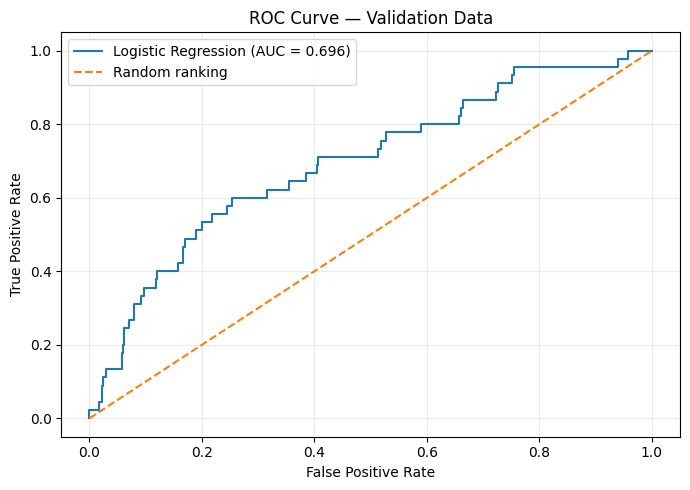

ROC-AUC: 0.696


In [16]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, roc_thresholds = roc_curve(y_validation, validation_probabilities)
roc_auc = roc_auc_score(y_validation, validation_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Validation Data")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")

### Interpret ROC-AUC carefully

ROC-AUC summarizes ranking performance across thresholds. A value closer to 1 indicates better separation between positive and negative examples; a value around 0.5 indicates ranking similar to random ordering.

A useful interpretation is: ROC-AUC estimates the probability that a randomly selected positive example receives a higher score than a randomly selected negative example.

ROC-AUC does **not** identify the best operating threshold, guarantee calibrated probabilities, or describe the business cost of errors.

### Exercise 7 — ROC interpretation

1. What does the diagonal reference line represent?
2. What does a higher true positive rate mean?
3. What does a lower false positive rate mean?
4. Can a model with a strong ROC-AUC still have poor precision at a chosen threshold? Explain.
5. Why does ROC-AUC not replace the confusion matrix?

## 8. Precision-recall analysis and average precision

The precision-recall (PR) curve plots precision against recall as the threshold changes.

It is especially useful when the positive class is relatively rare and the practical goal is to identify positive cases. Unlike ROC analysis, the PR curve focuses directly on positive-class retrieval.

The baseline precision of a no-skill ranking is related to the positive-class prevalence in the evaluated data. Therefore, always report the class prevalence when interpreting PR results.

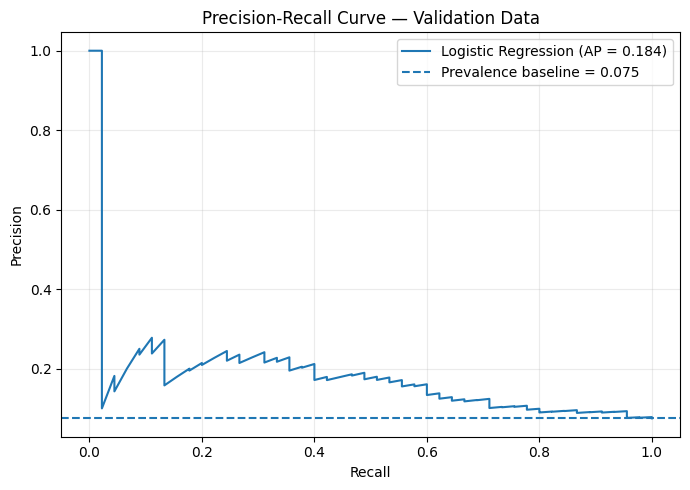

Average precision: 0.184
Positive-class prevalence: 0.075


In [17]:
from sklearn.metrics import precision_recall_curve, average_precision_score

pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_validation, validation_probabilities
)
average_precision = average_precision_score(y_validation, validation_probabilities)
positive_prevalence = y_validation.mean()

plt.figure(figsize=(7, 5))
plt.plot(pr_recall, pr_precision, label=f"Logistic Regression (AP = {average_precision:.3f})")
plt.axhline(
    positive_prevalence, linestyle="--",
    label=f"Prevalence baseline = {positive_prevalence:.3f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Validation Data")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Average precision: {average_precision:.3f}")
print(f"Positive-class prevalence: {positive_prevalence:.3f}")

### ROC-AUC vs. Average Precision

| Measure | Main question | Useful perspective |
|---|---|---|
| ROC-AUC | How well does the model rank positives above negatives? | Considers TPR and FPR across thresholds |
| Average Precision | How well does the model retrieve positive cases as recall increases? | Focuses on the precision-recall trade-off |

Neither measure should be selected without understanding the business objective and class distribution. Use the curves to understand threshold behaviour, then choose an operating point using validation data and business constraints.

### Exercise 8 — Compare the curves

1. Why is the positive-class prevalence shown as a reference line on the PR plot?
2. Which curve would you inspect closely if returned orders were rare?
3. Does a high average precision guarantee that the model's probabilities are calibrated?
4. Why should the PR curve be interpreted together with the number of positive cases?

**Stretch:** Write two sentences explaining ROC-AUC and average precision to a non-technical operations manager.

## 9. Threshold analysis and business trade-offs

The default threshold of 0.50 is a convention, not a universal business rule. A lower threshold usually identifies more positive cases, which can increase recall while also increasing false positives. A higher threshold usually reduces alerts but may miss more positive cases.

Threshold selection should be based on validation data. The test set should be used only after the threshold and evaluation plan are finalized.

In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

threshold_values = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]
threshold_rows = []

for threshold in threshold_values:
    labels = (validation_probabilities >= threshold).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(
        y_validation, labels, labels=[0, 1]
    ).ravel()

    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_validation, labels, zero_division=0),
        "recall": recall_score(y_validation, labels, zero_division=0),
        "f1": f1_score(y_validation, labels, zero_division=0),
        "specificity": tn_t / (tn_t + fp_t) if (tn_t + fp_t) else 0,
        "orders_flagged": int(labels.sum()),
        "false_positives": int(fp_t),
        "false_negatives": int(fn_t)
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(3))

,threshold,precision,recall,f1,specificity,orders_flagged,false_positives,false_negatives
0,0.2,0.24,0.133,0.171,0.966,25,19,39
1,0.3,0.00,0.000,0.000,1.000,0,0,45
2,0.4,0.00,0.000,0.000,1.000,0,0,45
3,0.5,0.00,0.000,0.000,1.000,0,0,45
4,0.6,0.00,0.000,0.000,1.000,0,0,45
5,0.7,0.00,0.000,0.000,1.000,0,0,45
6,0.8,0.00,0.000,0.000,1.000,0,0,45


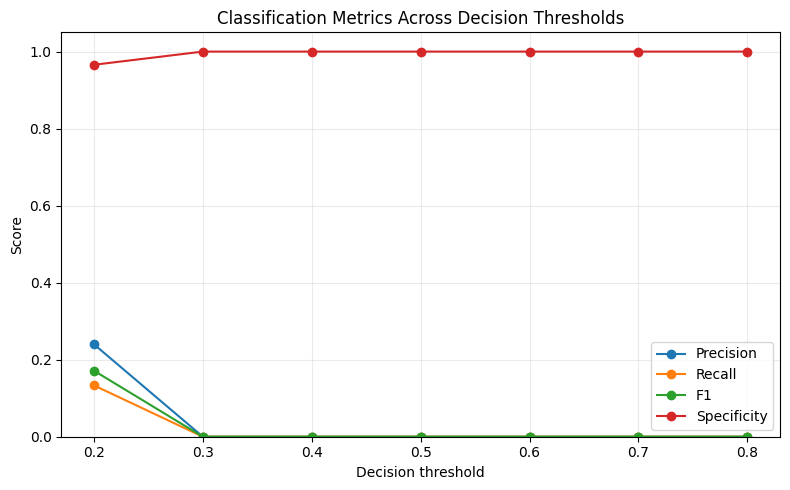

In [19]:
plt.figure(figsize=(8, 5))
for metric_name in ["precision", "recall", "f1", "specificity"]:
    plt.plot(
        threshold_results["threshold"],
        threshold_results[metric_name],
        marker="o",
        label=metric_name.replace("_", " ").title()
    )

plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Classification Metrics Across Decision Thresholds")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Add an operational capacity constraint

Suppose the AdventureWorks team can review no more than 120 orders from a daily batch. The threshold must therefore produce a manageable number of alerts.

For this exercise, use the validation set to find thresholds that flag no more than 120 orders. This is an illustration of capacity-based selection, not a universal threshold-selection method.

In [20]:
capacity_limit = 120

capacity_options = threshold_results[
    threshold_results["orders_flagged"] <= capacity_limit
].sort_values(["recall", "precision"], ascending=False)

display(capacity_options.head(10).round(3))

if not capacity_options.empty:
    capacity_threshold = float(capacity_options.iloc[0]["threshold"])
    print(f"Selected threshold under the capacity rule: {capacity_threshold:.2f}")
else:
    capacity_threshold = 0.50
    print("No tested threshold meets the capacity rule. Review the threshold grid.")

,threshold,precision,recall,f1,specificity,orders_flagged,false_positives,false_negatives
0,0.2,0.24,0.133,0.171,0.966,25,19,39
1,0.3,0.00,0.000,0.000,1.000,0,0,45
2,0.4,0.00,0.000,0.000,1.000,0,0,45
3,0.5,0.00,0.000,0.000,1.000,0,0,45
4,0.6,0.00,0.000,0.000,1.000,0,0,45
5,0.7,0.00,0.000,0.000,1.000,0,0,45
6,0.8,0.00,0.000,0.000,1.000,0,0,45


Selected threshold under the capacity rule: 0.20


### Cost-based threshold selection

Capacity is not the only possible decision rule. A business may estimate the relative cost of false positives and false negatives.

For a simplified example, assume:
- each false positive creates 1 cost unit of unnecessary review;
- each false negative creates 5 cost units because a likely return was missed.

The total cost at a threshold is:

\[
Total\ Cost = 1 \times FP + 5 \times FN
\]

These values are illustrative assumptions for training. In a real project, costs should be estimated with business stakeholders and tested through sensitivity analysis.

In [21]:
fp_cost = 1
fn_cost = 5

cost_rows = []
for threshold in np.linspace(0.10, 0.90, 17):
    labels = (validation_probabilities >= threshold).astype(int)
    tn_c, fp_c, fn_c, tp_c = confusion_matrix(
        y_validation, labels, labels=[0, 1]
    ).ravel()

    cost_rows.append({
        "threshold": threshold,
        "FP": fp_c,
        "FN": fn_c,
        "total_cost": fp_cost * fp_c + fn_cost * fn_c,
        "alerts": int(labels.sum())
    })

cost_results = pd.DataFrame(cost_rows)
display(cost_results.round(3))

best_cost_row = cost_results.loc[cost_results["total_cost"].idxmin()]
cost_threshold = float(best_cost_row["threshold"])
print(f"Lowest-cost threshold in this search: {cost_threshold:.2f}")

,threshold,FP,FN,total_cost,alerts
0,0.10,145,18,235,172
1,0.15,57,29,202,73
2,0.20,19,39,214,25
3,0.25,5,44,225,6
4,0.30,0,45,225,0
5,0.35,0,45,225,0
6,0.40,0,45,225,0
7,0.45,0,45,225,0
8,0.50,0,45,225,0
9,0.55,0,45,225,0


Lowest-cost threshold in this search: 0.15


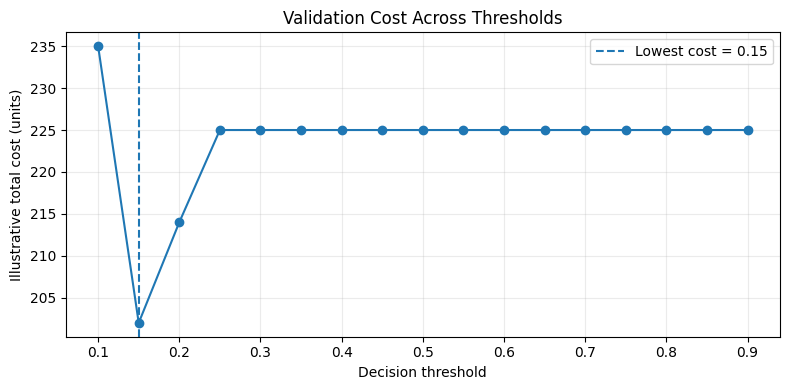

In [22]:
plt.figure(figsize=(8, 4))
plt.plot(cost_results["threshold"], cost_results["total_cost"], marker="o")
plt.axvline(cost_threshold, linestyle="--", label=f"Lowest cost = {cost_threshold:.2f}")
plt.xlabel("Decision threshold")
plt.ylabel("Illustrative total cost (units)")
plt.title("Validation Cost Across Thresholds")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Exercise 9 — Recommend a threshold

AdventureWorks has two competing priorities:

- The operations team wants to keep daily reviews within its capacity.
- The customer experience team wants to identify as many likely returns as possible.

1. Compare the threshold selected by the capacity rule with the threshold selected by the illustrative cost rule.
2. Which threshold produces more alerts?
3. Which threshold gives higher recall?
4. What assumptions are hidden in the cost values?
5. What additional information would you request before making a production recommendation?

There may be more than one defensible answer. Your recommendation must state its assumptions.

## 10. Probability quality and calibration

A classifier may rank cases well but produce probabilities that are not close to observed frequencies.

For example, among orders assigned a return probability near 0.70, we would expect approximately 70% to be returned if the probabilities are well calibrated over a sufficiently large group.

**Calibration** compares predicted probabilities with observed event frequencies. It is different from discrimination:

- **Discrimination:** can the model rank positive cases above negative cases?
- **Calibration:** do predicted probabilities match observed frequencies?

A model can have good ranking performance and still be poorly calibrated.

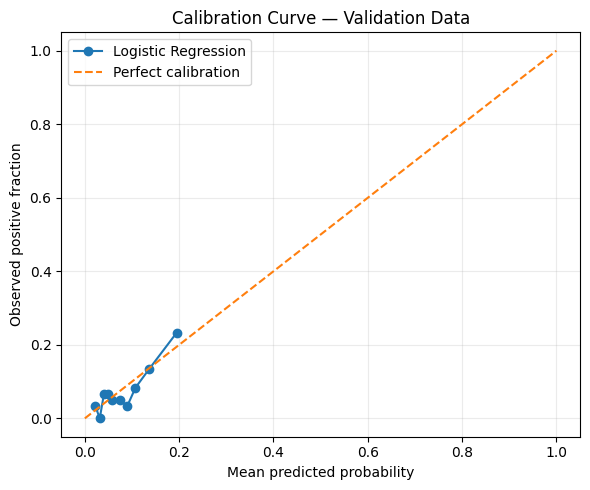

In [23]:
from sklearn.calibration import calibration_curve

observed_fraction, mean_predicted_value = calibration_curve(
    y_validation,
    validation_probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(6, 5))
plt.plot(mean_predicted_value, observed_fraction, marker="o", label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed positive fraction")
plt.title("Calibration Curve — Validation Data")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Brier score

The Brier score is the mean squared difference between predicted probabilities and actual binary outcomes:

\[
Brier = \frac{1}{N}\sum_{i=1}^{N}(p_i-y_i)^2
\]

For this loss, lower values are better. The score evaluates probability predictions, not just thresholded class labels. Its interpretation depends on the event prevalence and the difficulty of the prediction task, so compare it with an appropriate baseline.

In [24]:
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(y_validation, validation_probabilities)
prevalence_baseline_probabilities = np.full(
    shape=len(y_validation), fill_value=y_train.mean()
)
baseline_brier = brier_score_loss(
    y_validation, prevalence_baseline_probabilities
)

print(f"Model Brier score: {brier:.4f}")
print(f"Constant-prevalence baseline Brier score: {baseline_brier:.4f}")

Model Brier score: 0.0665
Constant-prevalence baseline Brier score: 0.0694


### Exercise 10 — Interpret probability quality

1. What does a perfectly calibrated model's curve look like?
2. What does a point above the diagonal indicate?
3. Why is calibration important if the business uses risk probabilities to prioritize work?
4. Why is calibration different from ROC-AUC?
5. Why should probability quality be checked on data not used to fit the model?

**Instructor note:** Avoid claiming that calibration alone makes a model useful. Ranking, decision costs, data quality, and operational impact still matter.

## 11. A structured model evaluation report

A professional evaluation report should be concise, reproducible, and connected to a decision. It should include:

1. **Evaluation design:** dataset, split strategy, and positive class.
2. **Class distribution:** number and percentage of positive cases.
3. **Confusion matrix:** counts of TP, TN, FP, and FN.
4. **Threshold metrics:** precision, recall, specificity, F1, and balanced accuracy.
5. **Ranking metrics:** ROC-AUC and average precision.
6. **Probability quality:** Brier score and calibration observations, when probabilities are used.
7. **Business interpretation:** likely operational consequences of errors.
8. **Limitations:** synthetic data, assumptions, sample size, and issues that require further validation.
9. **Recommendation:** proposed threshold or next experiment, with rationale.

Do not present a metric without naming the dataset split and threshold where applicable.

In [25]:
# Final test evaluation at the threshold selected using validation data.
final_threshold = cost_threshold
final_test_predictions = (test_probabilities >= final_threshold).astype(int)

test_cm = confusion_matrix(y_test, final_test_predictions, labels=[0, 1])
tn_test, fp_test, fn_test, tp_test = test_cm.ravel()

test_metrics = {
    "Accuracy": accuracy_score(y_test, final_test_predictions),
    "Balanced accuracy": balanced_accuracy_score(y_test, final_test_predictions),
    "Precision (Returned)": precision_score(y_test, final_test_predictions, zero_division=0),
    "Recall (Returned)": recall_score(y_test, final_test_predictions, zero_division=0),
    "Specificity (Not returned)": tn_test / (tn_test + fp_test) if (tn_test + fp_test) else 0,
    "F1-score (Returned)": f1_score(y_test, final_test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Average precision": average_precision_score(y_test, test_probabilities),
    "Brier score": brier_score_loss(y_test, test_probabilities)
}

print(f"Final threshold selected on validation data: {final_threshold:.2f}")
print("\nTest confusion matrix:")
print(test_cm)
display(pd.Series(test_metrics, name="Test score").to_frame().round(3))

Final threshold selected on validation data: 0.15

Test confusion matrix:
[[506  48]
 [ 40   6]]


,Test score
Accuracy,0.853
Balanced accuracy,0.522
Precision (Returned),0.111
Recall (Returned),0.130
Specificity (Not returned),0.913
F1-score (Returned),0.120
ROC-AUC,0.647
Average precision,0.151
Brier score,0.070


### Draft an executive interpretation

Use the following structure to communicate the result:

- **Objective:** what the model is designed to identify.
- **Evaluation:** which data split and threshold were used.
- **Performance:** the most relevant metrics and confusion-matrix counts.
- **Business meaning:** what the false positives and false negatives mean.
- **Recommendation:** whether to continue testing, pilot the workflow, or improve the model.
- **Caveats:** what this evaluation cannot establish.

A test score is evidence about performance on this held-out sample. It is not a guarantee of future performance after business processes, customers, or product mix change.

### Exercise 11 — Write a model evaluation summary

Write a short report for the AdventureWorks operations manager. Your report must:

1. State that the positive class is Returned.
2. Name the threshold and explain how it was selected.
3. Include at least four relevant test metrics.
4. Explain one consequence of false positives and one consequence of false negatives.
5. State at least two limitations of this exercise.

Avoid statements such as “the model is perfect” or “the model will achieve the same results in production.”

## 12. Common evaluation mistakes

Review these practices before evaluating any classification model:

- **Using training performance as final evidence:** training metrics are usually optimistic.
- **Tuning on the test set:** repeated decisions based on test results weaken its role as an independent evaluation.
- **Reporting accuracy alone:** this can hide poor performance on a minority class.
- **Ignoring the positive class definition:** precision and recall depend on which class is treated as positive.
- **Comparing metrics at different thresholds without saying so:** thresholded metrics are not directly comparable unless the threshold is stated.
- **Using predicted labels for ROC-AUC:** ROC-AUC should use scores or probabilities, not only hard class labels.
- **Treating ROC-AUC as calibration:** ranking quality does not establish probability quality.
- **Ignoring prevalence:** especially important when interpreting precision-recall results.
- **Choosing a threshold without business input:** operational capacity and error costs matter.
- **Forgetting uncertainty and drift:** one held-out sample does not guarantee future performance.

### Exercise 12 — Spot the evaluation problem

Identify the problem in each statement and rewrite it correctly.

1. “The model achieved 99% training accuracy, so it is ready.”
2. “We selected the threshold that gave the best test F1.”
3. “The ROC-AUC is high, so the probabilities are accurate.”
4. “Accuracy is enough because it is the most familiar metric.”
5. “The model has 80% recall,” without stating the positive class or evaluation split.

## 13. Mini project — AdventureWorks Return-Risk Evaluation

### Business brief

AdventureWorks is considering a return-risk review workflow. The model produces a probability that an order will be returned. The operations team needs an evidence-based recommendation before running a pilot.

Your task is to evaluate the classifier, compare operating policies, and prepare a short recommendation.

### Required deliverables

1. A clear description of the positive class and evaluation design.
2. The class distribution for training, validation, and test sets.
3. A confusion matrix for the default threshold.
4. A metric comparison including accuracy, balanced accuracy, precision, recall, specificity, and F1.
5. ROC curve and ROC-AUC.
6. Precision-recall curve and average precision.
7. A threshold comparison table.
8. A capacity-based or cost-based threshold recommendation.
9. A probability calibration plot and Brier score.
10. A concise executive report with limitations.

### Rules

- Use validation data to choose the operating threshold.
- Use the test set once for final evaluation.
- Do not change the test set based on the results.
- Explain why your chosen metrics fit the business objective.
- Treat the data as synthetic training data, not evidence of real customer behaviour.

### Mini project workspace

Complete the tasks below in the code cells. Use the existing variables where appropriate, and add Markdown notes to explain your decisions.

**Task A — Baseline evaluation:** evaluate the default threshold of 0.50 on validation data.

**Task B — Operating policy:** compare at least five thresholds and select one using a stated business rule.

**Task C — Final test:** evaluate the selected threshold on the held-out test set.

**Task D — Communication:** prepare a short report for a non-technical manager.

In [26]:
# Task A — Baseline evaluation
# TODO: Calculate the confusion matrix and the following metrics on validation data:
# accuracy, balanced accuracy, precision, recall, specificity, and F1.

In [27]:
# Task B — Operating policy
# TODO: Compare at least five thresholds on validation data.
# Include: threshold, precision, recall, F1, false positives, false negatives, and alerts.

In [28]:
# Task C — Final test
# TODO: Apply your selected validation threshold to test_probabilities.
# Report the confusion matrix and the final test metrics.

In [29]:
# Task D — Executive report
# TODO: Write a short, evidence-based recommendation in Markdown.
# Include the positive class, threshold, key metrics, business trade-offs, and limitations.

## 14. Knowledge check

Answer the questions before reviewing the instructor solutions.

1. What does a false negative represent in the AdventureWorks use case?
2. Which metric answers: “When the model flags an order, how often is it correct?”
3. Which metric measures the proportion of actual positive cases identified?
4. Why can accuracy be misleading with imbalanced classes?
5. What is the difference between specificity and recall?
6. What does macro averaging do?
7. What does ROC-AUC measure?
8. Why can a precision-recall curve be useful for rare positive classes?
9. Why should threshold selection use validation data rather than test data?
10. What does a Brier score evaluate?
11. Does a high ROC-AUC prove that predicted probabilities are calibrated?
12. What information should accompany a reported precision or recall score?

## Instructor solutions

### Suggested answers

1. A returned order was predicted as not returned.
2. Precision.
3. Recall (sensitivity).
4. A majority-class model may achieve high accuracy while failing to identify the minority class.
5. Specificity measures correct identification of actual negatives; recall measures correct identification of actual positives.
6. It calculates the metric for each class and gives each class equal weight in the final average.
7. It summarizes how well the model ranks positive cases above negative cases across thresholds.
8. It focuses on precision and recall for the positive class and makes the positive-class prevalence relevant to interpretation.
9. The validation set supports development decisions; the test set should remain an independent final evaluation.
10. The quality of predicted probabilities by measuring their squared difference from actual binary outcomes.
11. No. ROC-AUC measures ranking/discrimination, not calibration.
12. The positive class, evaluation split, and threshold (for threshold-dependent metrics), along with class support or prevalence where relevant.

### Discussion guidance

Accept different threshold recommendations when learners state their assumptions and use the validation data correctly. The objective is not to find one universal threshold. It is to explain a defensible operating policy.

## Session summary

In this session, we moved from model predictions to evidence-based evaluation.

- The confusion matrix makes the four types of outcomes visible.
- Accuracy, precision, recall, specificity, F1, and balanced accuracy answer different questions.
- ROC-AUC evaluates ranking across thresholds.
- Precision-recall analysis focuses on positive-class retrieval.
- Threshold selection should reflect business costs and operational capacity.
- Calibration and the Brier score help assess probability quality.
- A final report must state the evaluation design, positive class, threshold, business implications, and limitations.

### Readiness checklist

Before moving to the next classification topic, make sure you can:

- [ ] Read a confusion matrix without confusing FP and FN.
- [ ] Explain when precision or recall should receive more attention.
- [ ] Explain why accuracy can be misleading.
- [ ] Interpret ROC-AUC and average precision correctly.
- [ ] Compare thresholds using validation data.
- [ ] Explain calibration in simple terms.
- [ ] Produce a short evaluation report for a business audience.

**Next step:** use these evaluation principles when comparing more advanced classification algorithms and model-selection strategies.

## References

- Scikit-learn User Guide — Metrics and scoring: https://scikit-learn.org/stable/modules/model_evaluation.html
- Scikit-learn API — `sklearn.metrics`: https://scikit-learn.org/stable/api/sklearn.metrics.html
- Scikit-learn User Guide — Precision-recall analysis: https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html

These references document the metric definitions and implementation details used in this notebook.